# Autoencoders com PyTorch: teoria e implementação

**Duração da prática:** cerca de 50 minutos (Prática I: 30 min · Prática II: 12 min · Fechamento: 8 min)
**Dataset:** MNIST (dígitos manuscritos 28×28, tons de cinza)
**Pré-requisitos:** redes densas, backpropagation e noções de `nn.Module` e `DataLoader`

## Objetivos

Ao final deste notebook você será capaz de:

1. Implementar um autoencoder (encoder + decoder) em PyTorch.
2. Treinar o modelo minimizando o erro de reconstrução e interpretar a curva de perda.
3. Avaliar a qualidade da reconstrução visualmente e numericamente.
4. Investigar o efeito da dimensão do espaço latente.
5. Treinar um autoencoder de remoção de ruído (*denoising*).
6. Visualizar o espaço latente em 2D.

## Roteiro

| Parte | Conteúdo |
|---|---|
| 0 | Setup e dados |
| 1 | Arquitetura (teoria + código) |
| 2 | Função de perda e treino |
| 3 | Avaliação e reconstruções |
| 4 | Experimento A: dimensão latente |
| 5 | Experimento B: denoising |
| 6 | Experimento C: espaço latente 2D |
| 7 | Extensão: autoencoder convolucional |

## 0. Setup e dados

### Ideia central

Um autoencoder é uma rede neural treinada para **copiar a entrada na saída**, mas com uma restrição: no meio da rede existe um **gargalo** (*bottleneck*) com menos dimensões que a entrada. Para conseguir reconstruir a imagem passando por esse gargalo, a rede é obrigada a aprender uma representação compacta, o **código latente** $z$.

Não existem rótulos no treinamento: o **alvo é a própria entrada**. Por isso dizemos que o aprendizado é *autossupervisionado*.

### Sobre o dataset

O MNIST tem 60.000 imagens de treino e 10.000 de teste, de 28×28 pixels. Usamos `ToTensor()`, que converte cada pixel para o intervalo $[0, 1]$. Isso é importante: a camada final do decoder usará `Sigmoid`, que também produz valores em $[0, 1]$, então a saída e o alvo ficam na mesma escala.

In [1]:
import copy
import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

Dispositivo: cuda


In [2]:
transform = transforms.ToTensor()  # uint8 [0, 255] -> float32 [0, 1], formato (1, 28, 28)

train_ds = datasets.MNIST("data", train=True, download=True, transform=transform)
test_ds = datasets.MNIST("data", train=False, download=True, transform=transform)

BATCH_SIZE = 128
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False)

x_exemplo, y_exemplo = next(iter(train_loader))
print("Formato do lote:", x_exemplo.shape)   # (128, 1, 28, 28)
print("Valores entre", x_exemplo.min().item(), "e", x_exemplo.max().item())

Formato do lote: torch.Size([128, 1, 28, 28])
Valores entre 0.0 e 1.0


O `DataLoader` entrega **lotes** (*mini-batches*) de 128 imagens. Note o formato `(128, 1, 28, 28)`: (lote, canais, altura, largura). O embaralhamento (`shuffle=True`) só é aplicado ao treino.

Vamos olhar algumas amostras:

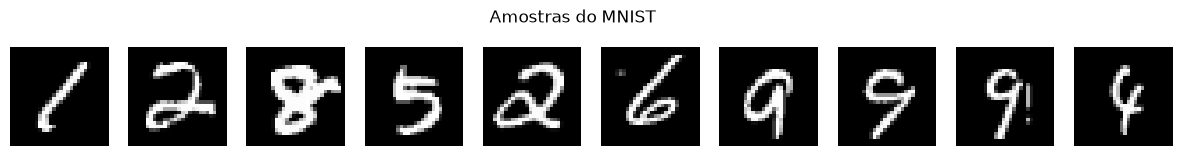

In [3]:
def mostrar_imagens(imagens, titulo="", n=10):
    fig, axs = plt.subplots(1, n, figsize=(1.5 * n, 1.8))
    for ax, img in zip(axs, imagens[:n]):
        ax.imshow(img.squeeze().cpu(), cmap="gray")
        ax.axis("off")
    fig.suptitle(titulo)
    plt.show()

mostrar_imagens(x_exemplo, "Amostras do MNIST")

## 1. Arquitetura

### Teoria

O autoencoder é composto por duas funções aprendidas:

$$z = f_\theta(x) \qquad\text{(encoder)}$$
$$\hat{x} = g_\phi(z) \qquad\text{(decoder)}$$

- $x \in \mathbb{R}^{784}$ é a imagem achatada (28×28).
- $z \in \mathbb{R}^{d}$ é o código latente, com $d < 784$ (*undercomplete*).
- $\hat{x} \in \mathbb{R}^{784}$ é a reconstrução.

**Por que o gargalo é essencial?** Se $d \geq 784$, a rede pode simplesmente aprender a função identidade e a perda iria a zero sem que nada útil fosse aprendido. Com $d$ pequeno, a rede precisa descartar o que é irrelevante e reter a estrutura principal dos dados.

**Quanto compressão?** Com $d = 32$ comprimimos 784 números em 32 (taxa de ≈ 24,5×).

### Implementação

Vamos usar uma rede densa (MLP) simétrica: $784 \to 128 \to d \to 128 \to 784$.

Pontos de implementação:

- `nn.Flatten()` achata `(N, 1, 28, 28)` em `(N, 784)` dentro do próprio encoder.
- O encoder termina **sem ativação**: o código latente é livre para assumir qualquer valor real.
- O decoder termina em **`Sigmoid`**, para a saída ficar em $[0, 1]$, como os pixels.
- O `forward` devolve a imagem reconstruída já no formato `(N, 1, 28, 28)`, para poder comparar diretamente com a entrada.

In [4]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=128, latent_dim=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid(),
        )

    def forward(self, x):
        z = self.encoder(x)              # (N, latent_dim)
        x_hat = self.decoder(z)          # (N, 784)
        return x_hat.view(-1, 1, 28, 28)

model = Autoencoder(latent_dim=32).to(device)
print(model)

n_params = sum(p.numel() for p in model.parameters())
print(f"Parâmetros treináveis: {n_params:,}")

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=784, bias=True)
    (3): Sigmoid()
  )
)
Parâmetros treináveis: 209,968


Teste rápido de formatos (*sanity check*): a saída deve ter o mesmo formato da entrada.

In [5]:
with torch.no_grad():
    saida = model(x_exemplo.to(device))
print("Entrada:", tuple(x_exemplo.shape), "-> Saída:", tuple(saida.shape))
assert saida.shape == x_exemplo.shape

Entrada: (128, 1, 28, 28) -> Saída: (128, 1, 28, 28)


## 2. Função de perda e treinamento

### Teoria

Queremos que $\hat{x}$ seja o mais parecido possível com $x$. A **perda de reconstrução** mede essa distância. Duas escolhas comuns:

**Erro quadrático médio (MSE)**, adequado para dados contínuos:
$$\mathcal{L}_{MSE} = \frac{1}{N}\sum_{i=1}^{N} \lVert x_i - \hat{x}_i \rVert^2$$

**Entropia cruzada binária (BCE)**, adequada quando as entradas estão em $[0,1]$ e podem ser vistas como probabilidades:
$$\mathcal{L}_{BCE} = -\frac{1}{N}\sum_{i}\sum_{j} \left[x_{ij}\log\hat{x}_{ij} + (1-x_{ij})\log(1-\hat{x}_{ij})\right]$$

Aqui usaremos **MSE** pela simplicidade. O treinamento é o de qualquer rede: calculamos a perda, retropropagamos o gradiente e atualizamos os pesos com o Adam.

### Implementação

O laço de treino segue sempre a mesma receita:

1. `optimizer.zero_grad()` — zera os gradientes acumulados.
2. `x_hat = model(x)` — passada direta.
3. `loss = criterion(x_hat, x)` — **o alvo é `x`, não o rótulo**.
4. `loss.backward()` — retropropagação.
5. `optimizer.step()` — atualização dos pesos.

Note que ignoramos os rótulos (`_`) retornados pelo `DataLoader`.

In [6]:
def avaliar(model, loader, criterion, ruido=0.0):
    """Perda média no conjunto (sem calcular gradientes)."""
    model.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for x, _ in loader:
            x = x.to(device)
            entrada = adicionar_ruido(x, ruido) if ruido > 0 else x
            x_hat = model(entrada)
            total += criterion(x_hat, x).item() * x.size(0)
            n += x.size(0)
    return total / n


def adicionar_ruido(x, std):
    """Soma ruído gaussiano e mantém os pixels em [0, 1]."""
    return (x + std * torch.randn_like(x)).clamp(0.0, 1.0)


def treinar(model, train_loader, test_loader, n_epochs=10, lr=1e-3, ruido=0.0, verbose=True):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    historico = {"treino": [], "teste": []}

    for epoca in range(1, n_epochs + 1):
        model.train()
        perdas = []
        for x, _ in train_loader:
            x = x.to(device)
            entrada = adicionar_ruido(x, ruido) if ruido > 0 else x

            optimizer.zero_grad()
            x_hat = model(entrada)
            loss = criterion(x_hat, x)      # alvo = imagem limpa
            loss.backward()
            optimizer.step()
            perdas.append(loss.item())

        perda_treino = float(np.mean(perdas))
        perda_teste = avaliar(model, test_loader, criterion, ruido)
        historico["treino"].append(perda_treino)
        historico["teste"].append(perda_teste)
        if verbose:
            print(f"Época {epoca:2d} | treino {perda_treino:.5f} | teste {perda_teste:.5f}")
    return model, historico

> **Observação sobre o parâmetro `ruido`:** com `ruido=0` o modelo é um autoencoder comum. Com `ruido>0` a **entrada** é corrompida mas o **alvo continua limpo**. Voltaremos a isso no Experimento B.

Vamos treinar por 10 épocas (em CPU leva poucos minutos):

In [7]:
torch.manual_seed(SEED)
model = Autoencoder(latent_dim=32).to(device)
model, hist = treinar(model, train_loader, test_loader, n_epochs=10)

Época  1 | treino 0.04823 | teste 0.02551
Época  2 | treino 0.02085 | teste 0.01693
Época  3 | treino 0.01521 | teste 0.01323
Época  4 | treino 0.01271 | teste 0.01155
Época  5 | treino 0.01134 | teste 0.01054
Época  6 | treino 0.01038 | teste 0.00977
Época  7 | treino 0.00976 | teste 0.00931
Época  8 | treino 0.00930 | teste 0.00899
Época  9 | treino 0.00889 | teste 0.00852
Época 10 | treino 0.00854 | teste 0.00819


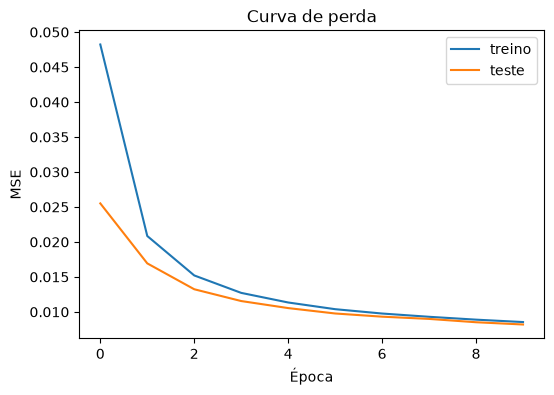

In [8]:
plt.figure(figsize=(6, 4))
plt.plot(hist["treino"], label="treino")
plt.plot(hist["teste"], label="teste")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.title("Curva de perda")
plt.legend()
plt.show()

**Como interpretar a curva:**

- Perda de treino e teste decrescendo juntas indicam que o modelo está aprendendo uma representação que generaliza.
- Se a perda de treino continuar caindo enquanto a de teste sobe, há *overfitting* (a rede está memorizando).
- Uma perda que estabiliza cedo sugere capacidade limitada (gargalo pequeno demais ou rede rasa).

## 3. Avaliação e reconstruções

Além da perda numérica, o autoencoder deve ser avaliado **visualmente**: a imagem reconstruída preserva a identidade do dígito? Perde detalhes finos?

Compare a linha de cima (originais) com a de baixo (reconstruções).

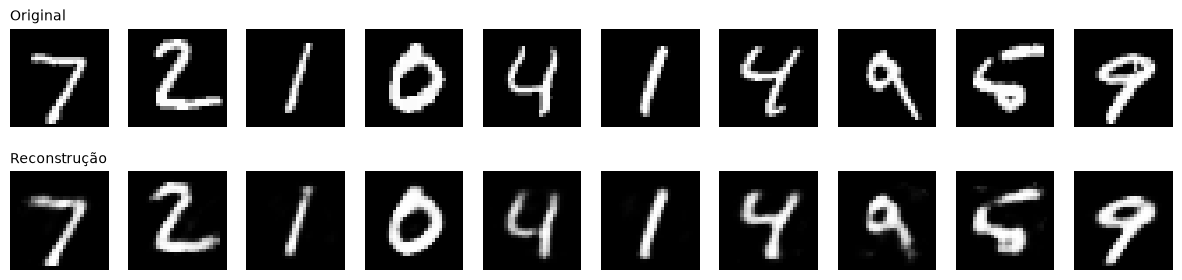

MSE no teste: 0.00819374018162489


In [9]:
def comparar_reconstrucoes(model, loader, n=10, ruido=0.0):
    model.eval()
    x, _ = next(iter(loader))
    x = x[:n].to(device)
    entrada = adicionar_ruido(x, ruido) if ruido > 0 else x
    with torch.no_grad():
        x_hat = model(entrada)

    linhas = [("Original", x)]
    if ruido > 0:
        linhas.append(("Entrada com ruído", entrada))
    linhas.append(("Reconstrução", x_hat))

    fig, axs = plt.subplots(len(linhas), n, figsize=(1.5 * n, 1.7 * len(linhas)))
    for r, (nome, imgs) in enumerate(linhas):
        for c in range(n):
            axs[r, c].imshow(imgs[c].squeeze().cpu(), cmap="gray")
            axs[r, c].axis("off")
        axs[r, 0].set_title(nome, loc="left", fontsize=10)
    plt.show()

comparar_reconstrucoes(model, test_loader)
print("MSE no teste:", avaliar(model, test_loader, nn.MSELoss()))

Repare que as reconstruções são ligeiramente **borradas**. Isso é típico: o MSE penaliza erros grandes e o modelo aprende a "média" provável, suavizando bordas. Variantes como autoencoders convolucionais ou perdas perceptuais reduzem esse efeito.

## 4. Experimento A: efeito da dimensão latente

**Hipótese:** quanto menor o gargalo, maior a perda de informação e pior a reconstrução.

Vamos treinar modelos com $d \in \{2, 8, 32\}$ por 5 épocas cada e comparar o MSE no teste e as reconstruções.

In [10]:
dims = [2, 8, 32]
modelos_dim, resultados = {}, {}

for d in dims:
    torch.manual_seed(SEED)
    m = Autoencoder(latent_dim=d).to(device)
    m, h = treinar(m, train_loader, test_loader, n_epochs=5, verbose=False)
    modelos_dim[d] = m
    resultados[d] = h["teste"][-1]
    print(f"latente = {d:2d} | MSE teste = {resultados[d]:.5f}")

latente =  2 | MSE teste = 0.04681
latente =  8 | MSE teste = 0.02271
latente = 32 | MSE teste = 0.01054


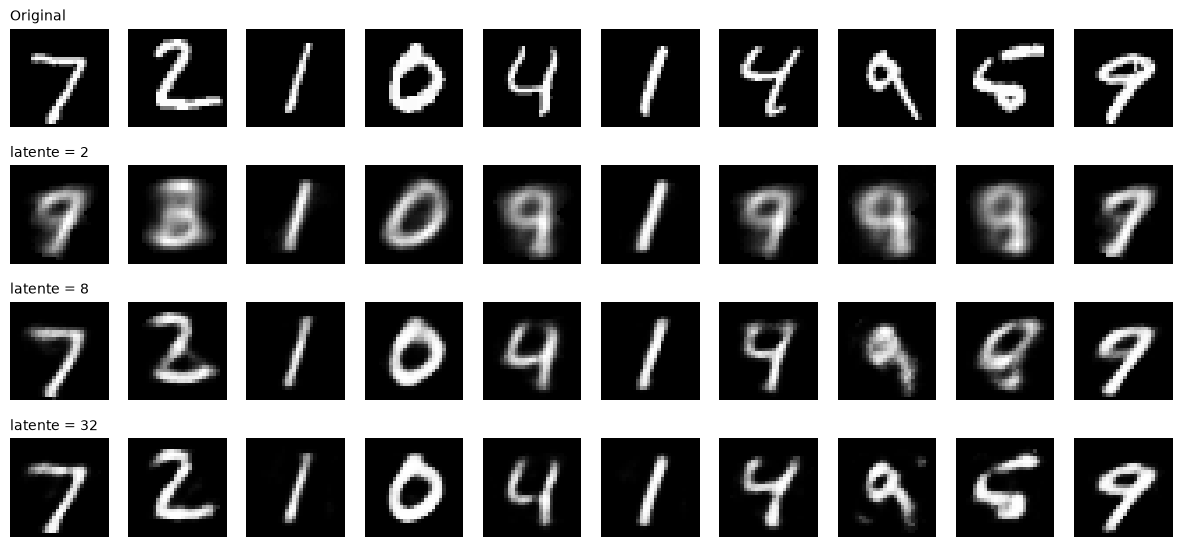

In [11]:
x, _ = next(iter(test_loader))
x = x[:10].to(device)

fig, axs = plt.subplots(len(dims) + 1, 10, figsize=(15, 1.7 * (len(dims) + 1)))
for c in range(10):
    axs[0, c].imshow(x[c].squeeze().cpu(), cmap="gray"); axs[0, c].axis("off")
axs[0, 0].set_title("Original", loc="left", fontsize=10)

for r, d in enumerate(dims, start=1):
    modelos_dim[d].eval()
    with torch.no_grad():
        x_hat = modelos_dim[d](x)
    for c in range(10):
        axs[r, c].imshow(x_hat[c].squeeze().cpu(), cmap="gray"); axs[r, c].axis("off")
    axs[r, 0].set_title(f"latente = {d}", loc="left", fontsize=10)
plt.show()

**Discussão:**

- Com $d=2$ muitos dígitos ficam confusos: 2 números não bastam para descrever todos os estilos de escrita.
- Com $d=32$ a reconstrução é bem mais fiel.
- Há um **compromisso** (*trade-off*) entre compressão e fidelidade. A escolha de $d$ é um hiperparâmetro.

## 5. Experimento B: autoencoder de remoção de ruído (denoising)

### Teoria

Um problema do autoencoder comum é que, se a capacidade é grande, ele pode apenas memorizar. No **denoising autoencoder** (Vincent et al., 2008) corrompemos a entrada e pedimos a reconstrução da versão **limpa**:

$$\tilde{x} = x + \epsilon,\quad \epsilon \sim \mathcal{N}(0, \sigma^2) \qquad\Rightarrow\qquad \min\ \lVert x - g(f(\tilde{x})) \rVert^2$$

Para desfazer o ruído, a rede precisa aprender a **estrutura** dos dados, e não apenas copiá-los. É uma forma de regularização.

### Implementação

Nada muda na arquitetura. Só a entrada do modelo passa por `adicionar_ruido`, enquanto a perda continua comparando com a imagem limpa (já implementado em `treinar` pelo argumento `ruido`).

Época  1 | treino 0.05166 | teste 0.03144
Época  2 | treino 0.02763 | teste 0.02437
Época  3 | treino 0.02313 | teste 0.02114
Época  4 | treino 0.02052 | teste 0.01923
Época  5 | treino 0.01886 | teste 0.01788


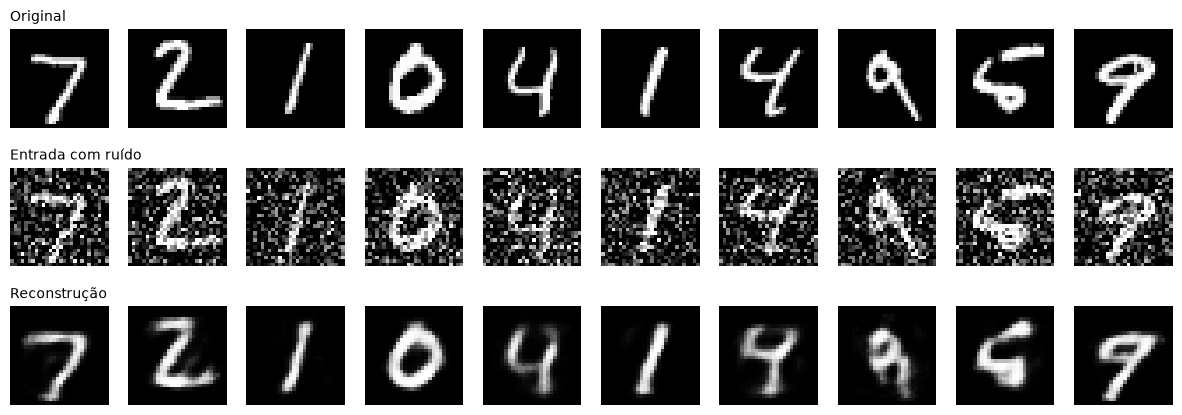

In [12]:
SIGMA = 0.4

torch.manual_seed(SEED)
modelo_dn = Autoencoder(latent_dim=32).to(device)
modelo_dn, hist_dn = treinar(modelo_dn, train_loader, test_loader, n_epochs=5, ruido=SIGMA)

comparar_reconstrucoes(modelo_dn, test_loader, ruido=SIGMA)

**Pergunta:** o que acontece se você aplicar o autoencoder comum (treinado sem ruído) às imagens ruidosas? Teste abaixo e compare.

MSE (modelo comum, entrada ruidosa):      0.04706929000020027
MSE (modelo denoising, entrada ruidosa):  0.01786992651373148


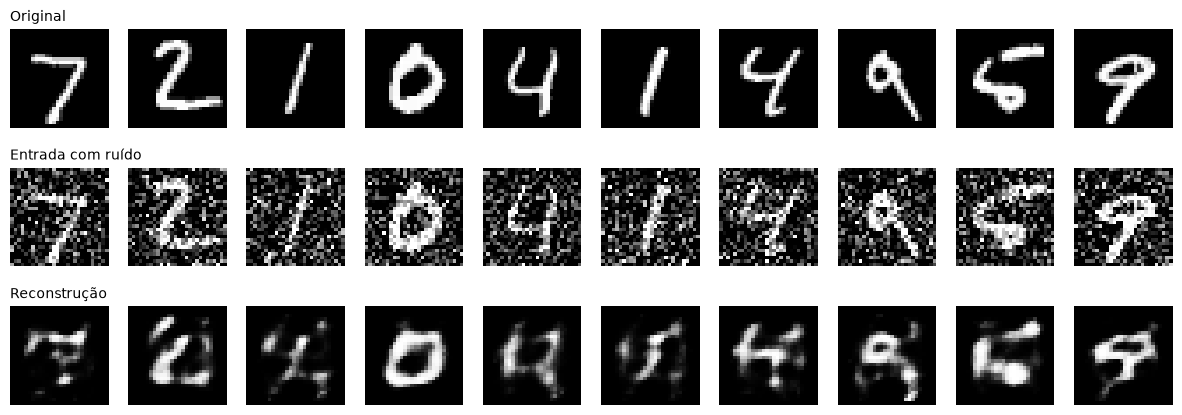

In [13]:
print("MSE (modelo comum, entrada ruidosa):     ", avaliar(model, test_loader, nn.MSELoss(), ruido=SIGMA))
print("MSE (modelo denoising, entrada ruidosa): ", avaliar(modelo_dn, test_loader, nn.MSELoss(), ruido=SIGMA))
comparar_reconstrucoes(model, test_loader, ruido=SIGMA)

## 6. Experimento C: espaço latente 2D

### Teoria

Se $d=2$, cada imagem vira um ponto num plano e podemos **visualizar** como o encoder organiza os dados. Mesmo sem nunca ter visto rótulos, o modelo tende a agrupar dígitos parecidos. Ao colorir os pontos pela classe real (apenas para visualização), avaliamos se o espaço latente capturou a estrutura semântica.

Observe também que o espaço **não é regular**: há regiões vazias e sobreposição entre classes. Esse é o ponto de partida para os autoencoders variacionais (VAE), que regularizam o espaço latente.

### Implementação

Basta aplicar apenas o `encoder` ao conjunto de teste, sem gradientes.

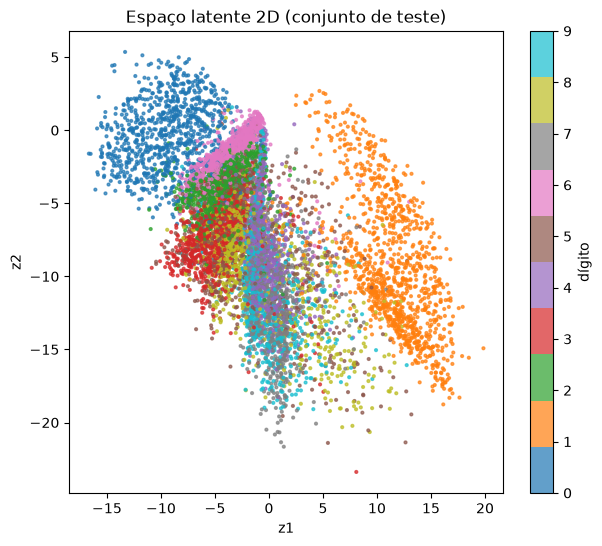

In [14]:
modelo_2d = modelos_dim[2]
modelo_2d.eval()

zs, ys = [], []
with torch.no_grad():
    for x, y in test_loader:
        zs.append(modelo_2d.encoder(x.to(device)).cpu())
        ys.append(y)
zs = torch.cat(zs).numpy()
ys = torch.cat(ys).numpy()

plt.figure(figsize=(7, 6))
sc = plt.scatter(zs[:, 0], zs[:, 1], c=ys, cmap="tab10", s=4, alpha=0.7)
plt.colorbar(sc, ticks=range(10), label="dígito")
plt.xlabel("z1"); plt.ylabel("z2")
plt.title("Espaço latente 2D (conjunto de teste)")
plt.show()

**Bônus:** como o decoder é uma função de $z$, podemos **gerar** imagens a partir de pontos arbitrários do plano. Pontos em regiões densas geram dígitos reconhecíveis; pontos em regiões vazias geram "lixo". Isso mostra a limitação do autoencoder simples como modelo gerador.

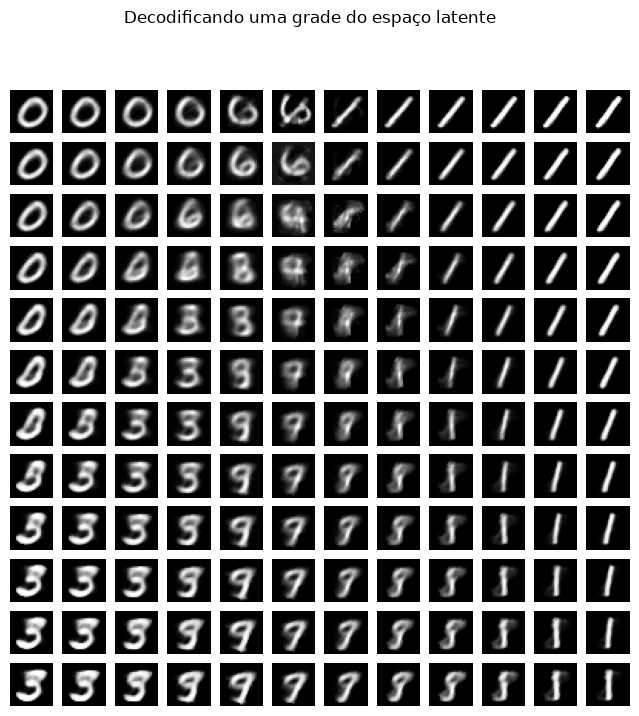

In [15]:
n = 12
xs = np.linspace(np.percentile(zs[:, 0], 2), np.percentile(zs[:, 0], 98), n)
ys_ = np.linspace(np.percentile(zs[:, 1], 98), np.percentile(zs[:, 1], 2), n)

grade = torch.tensor([[a, b] for b in ys_ for a in xs], dtype=torch.float32).to(device)
with torch.no_grad():
    imgs = modelo_2d.decoder(grade).view(-1, 28, 28).cpu()

fig, axs = plt.subplots(n, n, figsize=(8, 8))
for ax, img in zip(axs.flat, imgs):
    ax.imshow(img, cmap="gray"); ax.axis("off")
plt.suptitle("Decodificando uma grade do espaço latente")
plt.show()

## 7. Extensão: autoencoder convolucional

Para imagens, camadas convolucionais aproveitam a estrutura espacial e usam muito menos parâmetros que camadas densas.

- **Encoder:** `Conv2d` com `stride=2` reduz a resolução (28 → 14 → 7) enquanto aumenta o número de canais.
- **Decoder:** `ConvTranspose2d` com `stride=2` faz o caminho inverso (7 → 14 → 28). O `output_padding=1` garante o tamanho exato.

Os parâmetros de cada convolução seguem a fórmula do tamanho de saída: $\lfloor (n + 2p - k)/s \rfloor + 1$.

Parâmetros (conv): 111521
Parâmetros (MLP):  209968
Época  1 | treino 0.05358 | teste 0.01603
Época  2 | treino 0.01210 | teste 0.00933
Época  3 | treino 0.00869 | teste 0.00763
Época  4 | treino 0.00742 | teste 0.00678
Época  5 | treino 0.00673 | teste 0.00630


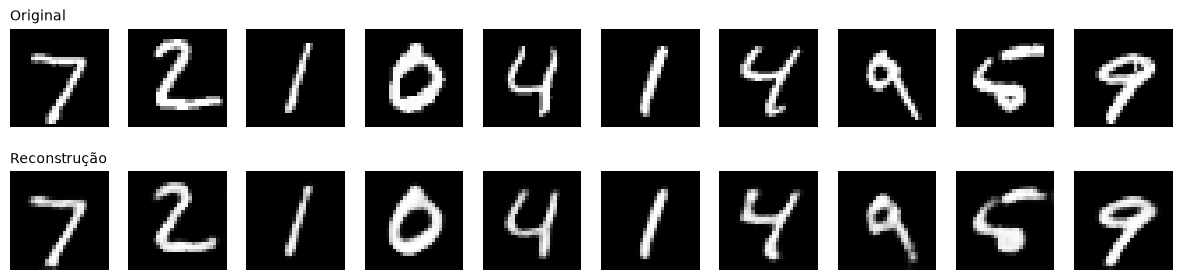

In [16]:
class ConvAutoencoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),   # 28 -> 14
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),  # 14 -> 7
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32 * 7 * 7),
            nn.ReLU(),
            nn.Unflatten(1, (32, 7, 7)),
            nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1),  # 7 -> 14
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1),   # 14 -> 28
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

torch.manual_seed(SEED)
modelo_conv = ConvAutoencoder(latent_dim=32).to(device)
print("Parâmetros (conv):", sum(p.numel() for p in modelo_conv.parameters()))
print("Parâmetros (MLP): ", sum(p.numel() for p in model.parameters()))

modelo_conv, hist_conv = treinar(modelo_conv, train_loader, test_loader, n_epochs=5)
comparar_reconstrucoes(modelo_conv, test_loader)

## 8. Fechamento

### O que aprendemos

- Autoencoders aprendem a **reconstruir a própria entrada** passando por um gargalo; o alvo é a entrada (sem rótulos).
- O **tamanho do código latente** controla o compromisso entre compressão e fidelidade.
- O **denoising** força a rede a aprender estrutura, e não a identidade.
- O espaço latente de um autoencoder simples é útil, porém **irregular**, o que motiva os VAEs.
- A **reconstrução borrada** é uma limitação conhecida do MSE.

### Perguntas para fixar

1. O que aconteceria se `latent_dim = 784` e não houvesse regularização?
2. Por que o decoder termina em `Sigmoid`? E o que muda se normalizarmos as imagens para $[-1, 1]$?
3. Em que situação o erro de reconstrução pode ser usado para detectar anomalias?
4. Por que o autoencoder linear com MSE é equivalente ao PCA?

### Tarefa de casa

Implemente um **autoencoder convolucional de remoção de ruído** no **Fashion-MNIST** (`datasets.FashionMNIST`) e compare as reconstruções para três níveis de ruído ($\sigma = 0{,}1;\ 0{,}3;\ 0{,}5$). Escreva um relatório de uma página.

### Próximos passos

Aplique estas ideias a séries temporais no **notebook-desafio** (LSTM autoencoder para detectar batimentos anômalos em ECG).

### Referências

- Hinton, G.; Salakhutdinov, R. *Reducing the dimensionality of data with neural networks.* Science, 2006.
- Vincent, P. et al. *Extracting and composing robust features with denoising autoencoders.* ICML, 2008.
- Kingma, D.; Welling, M. *Auto-encoding variational Bayes.* 2013.
- Goodfellow, I.; Bengio, Y.; Courville, A. *Deep Learning*, cap. 14 (Autoencoders).